# 02 - Model Development and Experiment Tracking

Models are selected, tuned and compared on the cleaned heart disease data, and
the runs are recorded in MLflow. The steps common to all models are functions
in `src/`.

1. Data split
2. Evaluation method
3. Model selection
4. `ca` as categorical or numerical
5. Logistic Regression
6. Random Forest
7. Gradient Boosting

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.base import clone
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression

# project root, one level above notebooks/
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

from src.data_prep import CATEGORICAL, NUMERIC
from src.evaluation import (
    RANDOM_STATE,
    build_metrics_table,
    create_cv_folds,
    cross_val_probabilities,
    plot_confusion_matrix,
    plot_roc_curve,
    readable_metrics,
    run_grid_search,
    split_data,
)
from src.preprocessing import make_pipeline
from src.tracking import log_model_runs

pd.set_option("display.width", 200)

## 1. Data split

80% training and 20% test, stratified, with a fixed seed. The test set is
used only once, at the end, for the champion model.

In [2]:
X_train, X_test, y_train, y_test = split_data()

split = pd.DataFrame({
    "patients": [len(y_train), len(y_test)],
    "with disease": [int(y_train.sum()), int(y_test.sum())],
    "disease share (%)": [round(y_train.mean() * 100, 1), round(y_test.mean() * 100, 1)],
}, index=["training", "test"])
split

,patients,with disease,disease share (%)
training,242,111,45.9
test,61,28,45.9


The objective of the experiment is to select the best model. It has to beat
these scores, which can be got without learning anything from the data:

- Accuracy: about 54%. A model that predicts "no disease" for every patient
  gets this, because 54% of the patients do not have the disease.
- ROC-AUC: 0.5. Random guessing gives this.

## 2. Evaluation method

- 10-fold stratified cross-validation on the training patients.
- Metrics: accuracy, precision, recall, F1 and ROC-AUC, as mean and standard
  deviation over the folds.
- Grid search for tuning. The best setting of a model is the one with the
  highest mean ROC-AUC. If two settings are equal, the simpler one is taken.
- All runs are recorded in MLflow.

In [3]:
folds = create_cv_folds()
folds

StratifiedKFold(n_splits=10, random_state=42, shuffle=True)

## 3. Model selection

Points considered while choosing the models:

- Only 242 patients are available for training, so models that need a lot of
  data were left out.
- Each prediction has to come with its confidence, so the model must be able
  to give a probability.
- The EDA showed non-linear patterns, for example for `ca` and `slope`.
- The outliers were kept in the data.
- It should be possible to explain a prediction.

Models selected:

- Logistic Regression: simple and easy to explain. Used as the reference
  model.
- Random Forest: handles non-linear patterns and outliers.
- Gradient Boosting: tree-based and usually accurate on table data, but can
  overfit small data.
- Support Vector Machine: a different approach that works well on small data.
  It is the hardest to explain.

## 4. `ca` as categorical or numerical

`ca` is a count from 0 to 3. In the EDA it was treated as categorical, because
the disease share did not rise in equal steps with the count (notebook 01,
section 11). Both forms are tried here on the reference model with its default
setting (`C` = 1), on the same folds.

In [4]:
model_name = "Logistic Regression"
default_grid = {"model__C": [1.0]}

# ca moved from the categorical list to the numerical list
numeric_with_ca = NUMERIC + ["ca"]
categorical_without_ca = CATEGORICAL.copy()
categorical_without_ca.remove("ca")

ca_pipelines = {
    "categorical": make_pipeline(LogisticRegression(random_state=RANDOM_STATE)),
    "numerical": make_pipeline(
        LogisticRegression(random_state=RANDOM_STATE),
        numeric=numeric_with_ca,
        categorical=categorical_without_ca,
    ),
}

ca_tables = []
for ca_form, ca_pipeline in ca_pipelines.items():
    ca_search = run_grid_search(ca_pipeline, default_grid, X_train, y_train, folds)
    ca_table = build_metrics_table(ca_search)
    log_model_runs(
        f"{model_name} (ca {ca_form})", ca_pipeline, ca_search, ca_table,
        X_train, y_train, folds, tags={"experiment": "ca form"},
    )
    ca_table.insert(0, "ca", ca_form)
    ca_tables.append(ca_table)

readable_metrics(pd.concat(ca_tables, ignore_index=True))

Logged to MLflow: Logistic Regression (ca categorical), 1 combinations.
Logged to MLflow: Logistic Regression (ca numerical), 1 combinations.


,ca,C,accuracy,precision,recall,f1,roc_auc
0,categorical,1.0,0.847 ± 0.063,0.879 ± 0.100,0.793 ± 0.107,0.826 ± 0.066,0.904 ± 0.052
1,numerical,1.0,0.831 ± 0.055,0.856 ± 0.091,0.776 ± 0.106,0.807 ± 0.061,0.907 ± 0.050


Observations

The two forms give almost the same result. ROC-AUC is 0.904 with `ca` as
categorical and 0.907 as numerical. This gap is much smaller than the standard
deviation across the folds (about 0.05). The other four metrics are slightly
higher for the categorical form. As there is no clear difference, `ca` is kept
as categorical, as decided in the EDA.

## 5. Logistic Regression

Reference model. The default L2 penalty is used and its strength `C` is tuned.
A smaller `C` gives a simpler model. The default value, `C` = 1, is one of the
values tried.

In [5]:
model_name = "Logistic Regression"

pipeline = make_pipeline(LogisticRegression(random_state=RANDOM_STATE))

# "model__C" is the setting C of the pipeline step named "model"
grid = {"model__C": [0.01, 0.1, 1, 10]}

In [6]:
search = run_grid_search(pipeline, grid, X_train, y_train, folds)
metrics_table = build_metrics_table(search)

print("Combinations tried:", len(metrics_table))
print("Best setting by ROC-AUC:", search.best_params_)

Combinations tried: 4
Best setting by ROC-AUC: {'model__C': 0.1}


In [7]:
# recorded in MLflow: a parent run for the model, a child run for each
# combination, and the trained model of the best setting
log_model_runs(model_name, pipeline, search, metrics_table, X_train, y_train, folds)

Logged to MLflow: Logistic Regression, 4 combinations.


In [8]:
# mean ± std over the 10 folds
readable_metrics(metrics_table)

,C,accuracy,precision,recall,f1,roc_auc
0,0.01,0.806 ± 0.069,0.880 ± 0.124,0.694 ± 0.082,0.768 ± 0.069,0.888 ± 0.059
1,0.10,0.831 ± 0.050,0.852 ± 0.097,0.784 ± 0.092,0.810 ± 0.049,0.905 ± 0.048
2,1.00,0.847 ± 0.063,0.879 ± 0.100,0.793 ± 0.107,0.826 ± 0.066,0.904 ± 0.052
3,10.00,0.839 ± 0.063,0.860 ± 0.097,0.794 ± 0.112,0.818 ± 0.067,0.902 ± 0.052


In [9]:
# default setting (C = 1) against the best setting
default_row = metrics_table[metrics_table["C"] == 1]
best_row = metrics_table.loc[[search.best_index_]]

comparison = pd.concat([default_row, best_row])
comparison.insert(0, "setting", ["default", "best"])
readable_metrics(comparison)

,setting,C,accuracy,precision,recall,f1,roc_auc
2,default,1.0,0.847 ± 0.063,0.879 ± 0.100,0.793 ± 0.107,0.826 ± 0.066,0.904 ± 0.052
1,best,0.1,0.831 ± 0.050,0.852 ± 0.097,0.784 ± 0.092,0.810 ± 0.049,0.905 ± 0.048


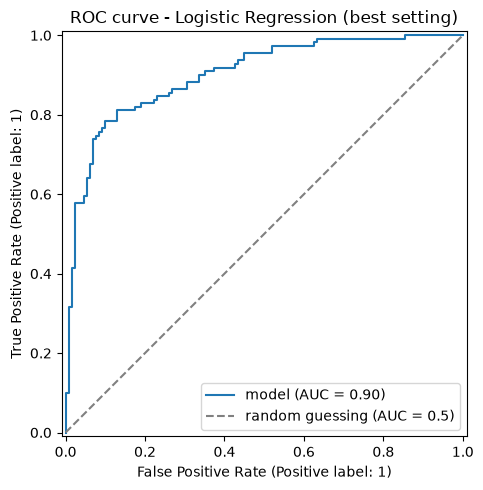

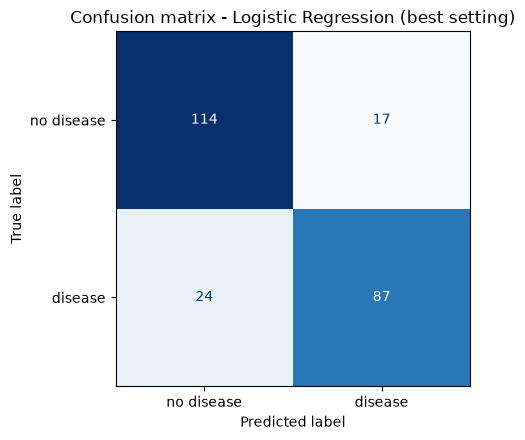

In [10]:
# plots for the best setting, from the cross-validation predictions
best_pipeline = clone(pipeline).set_params(**search.best_params_)
probability = cross_val_probabilities(best_pipeline, X_train, y_train, folds)

plot_roc_curve(y_train, probability, f"ROC curve - {model_name} (best setting)")
plot_confusion_matrix(y_train, probability, f"Confusion matrix - {model_name} (best setting)")
plt.show()

Observations

- The best setting is `C` = 0.1, with a mean ROC-AUC of 0.905.
- ROC-AUC stays between 0.902 and 0.905 for `C` = 0.1, 1 and 10, so the model
  is not sensitive to `C` in this range.
- Tuning gave no real gain over the default setting (0.905 against 0.904).

Recall is 0.784 at the best setting, so about 22% of the patients with disease
are missed.

## 6. Random Forest

An average of many decision trees. The size of each tree (`max_depth` and
`min_samples_leaf`) and the number of trees (`n_estimators`) are tuned. The
default setting (no depth limit, 1 patient in a leaf, 100 trees) is one of the
combinations tried.

In [11]:
model_name = "Random Forest"

pipeline = make_pipeline(RandomForestClassifier(random_state=RANDOM_STATE))

# each setting is written from the simplest value to the most complex
grid = {
    "model__max_depth": [3, 5, None],
    "model__min_samples_leaf": [5, 3, 1],
    "model__n_estimators": [100, 300],
}

In [12]:
search = run_grid_search(pipeline, grid, X_train, y_train, folds)
metrics_table = build_metrics_table(search)

print("Combinations tried:", len(metrics_table))
print("Best setting by ROC-AUC:", search.best_params_)

Combinations tried: 18
Best setting by ROC-AUC: {'model__max_depth': 5, 'model__min_samples_leaf': 3, 'model__n_estimators': 300}


In [13]:
# recorded in MLflow: a parent run for the model, a child run for each
# combination, and the trained model of the best setting
log_model_runs(model_name, pipeline, search, metrics_table, X_train, y_train, folds)

Logged to MLflow: Random Forest, 18 combinations.


In [14]:
# mean ± std over the 10 folds
readable_metrics(metrics_table)

,max_depth,min_samples_leaf,n_estimators,accuracy,precision,recall,f1,roc_auc
0,3,5,100,0.809 ± 0.044,0.831 ± 0.102,0.765 ± 0.117,0.784 ± 0.047,0.900 ± 0.041
1,3,5,300,0.814 ± 0.051,0.843 ± 0.115,0.765 ± 0.117,0.789 ± 0.052,0.904 ± 0.041
2,3,3,100,0.810 ± 0.043,0.833 ± 0.105,0.765 ± 0.117,0.785 ± 0.044,0.899 ± 0.041
3,3,3,300,0.814 ± 0.051,0.843 ± 0.115,0.765 ± 0.117,0.789 ± 0.052,0.904 ± 0.035
4,3,1,100,0.801 ± 0.053,0.834 ± 0.110,0.747 ± 0.135,0.772 ± 0.057,0.900 ± 0.039
5,3,1,300,0.818 ± 0.048,0.850 ± 0.110,0.765 ± 0.117,0.792 ± 0.048,0.899 ± 0.039
6,5,5,100,0.797 ± 0.064,0.820 ± 0.123,0.756 ± 0.116,0.774 ± 0.057,0.894 ± 0.042
7,5,5,300,0.805 ± 0.060,0.824 ± 0.117,0.765 ± 0.110,0.783 ± 0.059,0.902 ± 0.044
8,5,3,100,0.805 ± 0.057,0.831 ± 0.118,0.765 ± 0.117,0.783 ± 0.052,0.900 ± 0.043
9,5,3,300,0.810 ± 0.050,0.829 ± 0.115,0.774 ± 0.110,0.788 ± 0.048,0.905 ± 0.040


In [15]:
# default setting (no depth limit, 1 patient in a leaf, 100 trees) against
# the best setting
default_row = metrics_table[
    (metrics_table["max_depth"] == "None")
    & (metrics_table["min_samples_leaf"] == 1)
    & (metrics_table["n_estimators"] == 100)
]
best_row = metrics_table.loc[[search.best_index_]]

comparison = pd.concat([default_row, best_row])
comparison.insert(0, "setting", ["default", "best"])
readable_metrics(comparison)

,setting,max_depth,min_samples_leaf,n_estimators,accuracy,precision,recall,f1,roc_auc
16,default,None,1,100,0.793 ± 0.068,0.809 ± 0.123,0.756 ± 0.093,0.772 ± 0.062,0.889 ± 0.045
9,best,5,3,300,0.810 ± 0.050,0.829 ± 0.115,0.774 ± 0.110,0.788 ± 0.048,0.905 ± 0.040


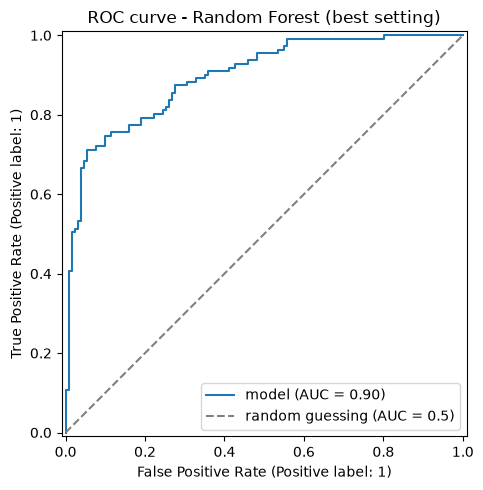

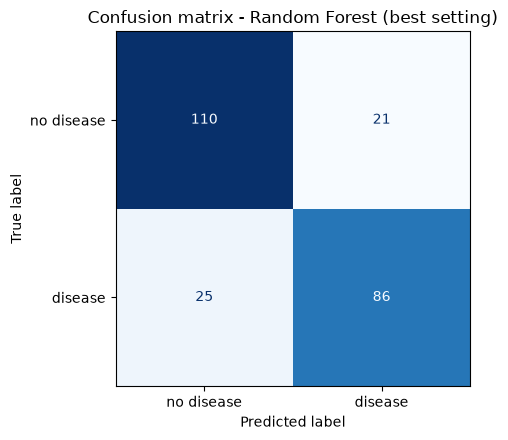

In [16]:
# plots for the best setting, from the cross-validation predictions
best_pipeline = clone(pipeline).set_params(**search.best_params_)
probability = cross_val_probabilities(best_pipeline, X_train, y_train, folds)

plot_roc_curve(y_train, probability, f"ROC curve - {model_name} (best setting)")
plot_confusion_matrix(y_train, probability, f"Confusion matrix - {model_name} (best setting)")
plt.show()

Observations

The best setting is `max_depth` = 5, `min_samples_leaf` = 3 and 300 trees, with
a mean ROC-AUC of 0.905. Tuning gave a small gain for this model. The fully
grown trees (no depth limit, 1 patient in a leaf), which include the default
setting, have the lowest ROC-AUC of all (0.889 and 0.888).

- Once the size of the trees is limited, the exact values matter little. All
  the other settings are between 0.894 and 0.905.
- The gain from 300 trees over 100 is small, 0.008 at most, and in two pairs
  100 trees are slightly higher.

Recall is 0.774 at the best setting, so about 23% of the patients with disease
are missed.

## 7. Gradient Boosting

Decision trees built one after another, each correcting the errors left by the
earlier ones. The depth of the trees (`max_depth`), the number of trees
(`n_estimators`) and the learning rate (`learning_rate`) are tuned. The
default setting (learning rate 0.1, depth 3, 100 trees) is one of the
combinations tried.

In [17]:
model_name = "Gradient Boosting"

pipeline = make_pipeline(GradientBoostingClassifier(random_state=RANDOM_STATE))

# each setting is written from the simplest value to the most complex
grid = {
    "model__learning_rate": [0.05, 0.1],
    "model__max_depth": [1, 2, 3],
    "model__n_estimators": [50, 100, 200],
}

In [18]:
search = run_grid_search(pipeline, grid, X_train, y_train, folds)
metrics_table = build_metrics_table(search)

print("Combinations tried:", len(metrics_table))
print("Best setting by ROC-AUC:", search.best_params_)

Combinations tried: 18
Best setting by ROC-AUC: {'model__learning_rate': 0.1, 'model__max_depth': 1, 'model__n_estimators': 50}


In [19]:
# recorded in MLflow: a parent run for the model, a child run for each
# combination, and the trained model of the best setting
log_model_runs(model_name, pipeline, search, metrics_table, X_train, y_train, folds)

Logged to MLflow: Gradient Boosting, 18 combinations.


In [20]:
# mean ± std over the 10 folds
readable_metrics(metrics_table)

,learning_rate,max_depth,n_estimators,accuracy,precision,recall,f1,roc_auc
0,0.05,1,50,0.835 ± 0.042,0.886 ± 0.103,0.757 ± 0.108,0.806 ± 0.055,0.890 ± 0.043
1,0.05,1,100,0.831 ± 0.034,0.873 ± 0.092,0.757 ± 0.091,0.803 ± 0.040,0.897 ± 0.040
2,0.05,1,200,0.814 ± 0.034,0.826 ± 0.083,0.775 ± 0.092,0.792 ± 0.038,0.890 ± 0.042
3,0.05,2,50,0.822 ± 0.057,0.845 ± 0.106,0.775 ± 0.109,0.799 ± 0.061,0.888 ± 0.046
4,0.05,2,100,0.798 ± 0.056,0.802 ± 0.094,0.767 ± 0.127,0.774 ± 0.065,0.886 ± 0.046
5,0.05,2,200,0.781 ± 0.057,0.796 ± 0.119,0.739 ± 0.101,0.756 ± 0.056,0.880 ± 0.049
6,0.05,3,50,0.785 ± 0.061,0.816 ± 0.119,0.721 ± 0.083,0.757 ± 0.055,0.875 ± 0.048
7,0.05,3,100,0.777 ± 0.056,0.778 ± 0.072,0.730 ± 0.105,0.748 ± 0.065,0.873 ± 0.056
8,0.05,3,200,0.777 ± 0.060,0.772 ± 0.082,0.748 ± 0.098,0.754 ± 0.063,0.861 ± 0.062
9,0.10,1,50,0.831 ± 0.043,0.866 ± 0.100,0.766 ± 0.083,0.806 ± 0.046,0.899 ± 0.038


In [21]:
# default setting (learning rate 0.1, depth 3, 100 trees) against the best
# setting
default_row = metrics_table[
    (metrics_table["learning_rate"] == 0.1)
    & (metrics_table["max_depth"] == 3)
    & (metrics_table["n_estimators"] == 100)
]
best_row = metrics_table.loc[[search.best_index_]]

comparison = pd.concat([default_row, best_row])
comparison.insert(0, "setting", ["default", "best"])
readable_metrics(comparison)

,setting,learning_rate,max_depth,n_estimators,accuracy,precision,recall,f1,roc_auc
16,default,0.1,3,100,0.777 ± 0.057,0.776 ± 0.079,0.739 ± 0.086,0.752 ± 0.058,0.860 ± 0.057
9,best,0.1,1,50,0.831 ± 0.043,0.866 ± 0.100,0.766 ± 0.083,0.806 ± 0.046,0.899 ± 0.038


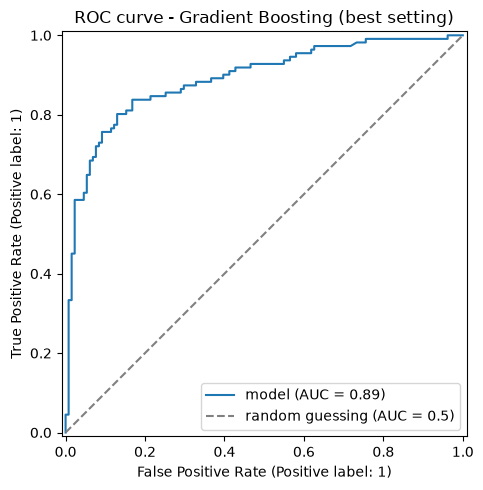

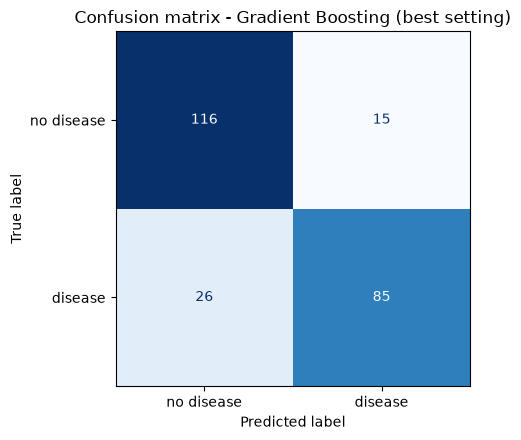

In [22]:
# plots for the best setting, from the cross-validation predictions
best_pipeline = clone(pipeline).set_params(**search.best_params_)
probability = cross_val_probabilities(best_pipeline, X_train, y_train, folds)

plot_roc_curve(y_train, probability, f"ROC curve - {model_name} (best setting)")
plot_confusion_matrix(y_train, probability, f"Confusion matrix - {model_name} (best setting)")
plt.show()

Observations

- The best setting is a learning rate of 0.1, `max_depth` = 1 and 50 trees,
  with a mean ROC-AUC of 0.899.
- The simpler settings do better. The highest ROC-AUC is 0.899 at depth 1,
  0.889 at depth 2 and 0.875 at depth 3.
- More trees do not help. At a learning rate of 0.1, ROC-AUC falls from 50 to
  200 trees at every depth.

Tuning mattered more for this model than for the other two. The default
setting has a ROC-AUC of 0.860, against 0.899 for the best setting. Recall is
0.766 at the best setting, so about 23% of the patients with disease are
missed.

## Viewing the runs in MLflow

```
mlflow ui --backend-store-uri sqlite:///mlflow.db --port 5000
```